In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report)

In [2]:
df=pd.read_csv("/content/iris.csv")

In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


In [5]:
df.shape

(150, 5)

In [6]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [7]:
df['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


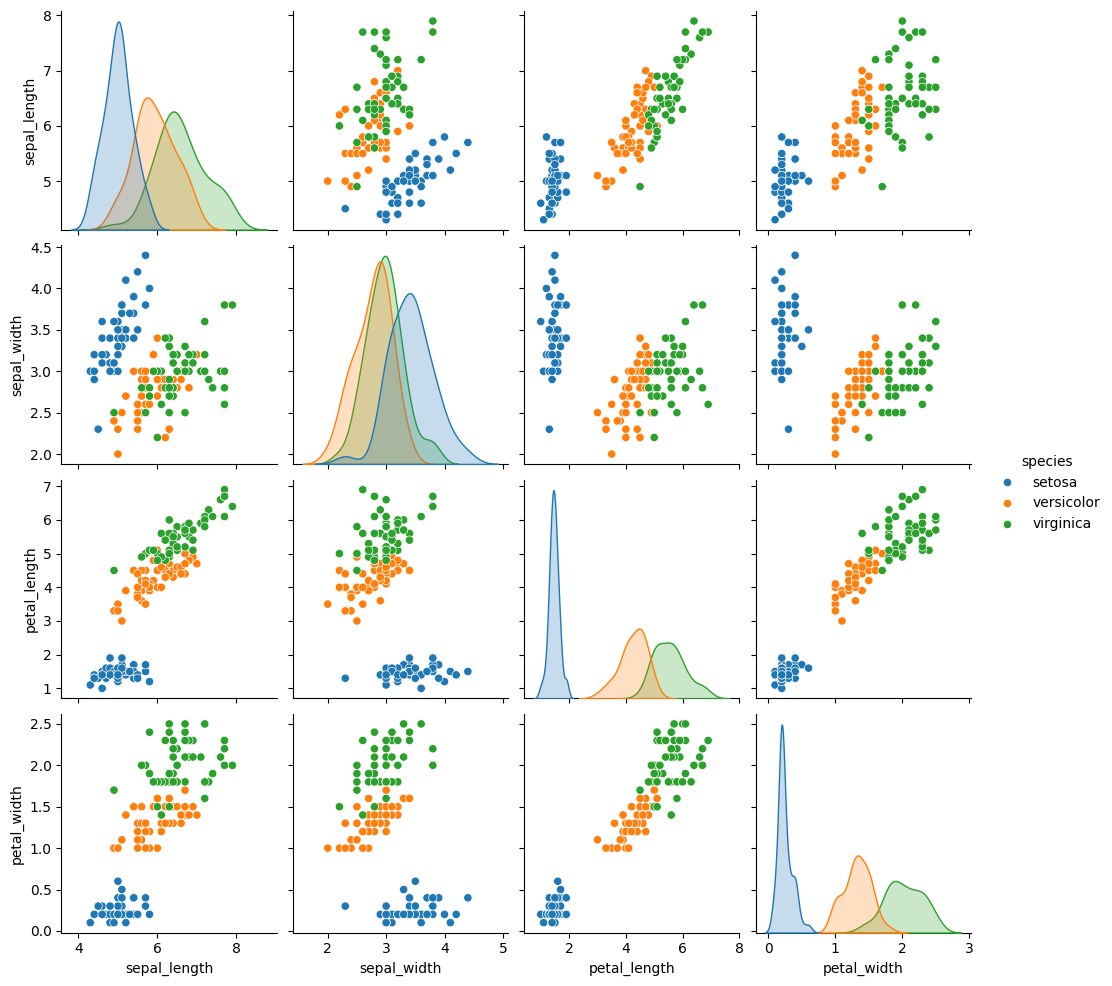

In [8]:
sns.pairplot(df, hue='species')
plt.show()

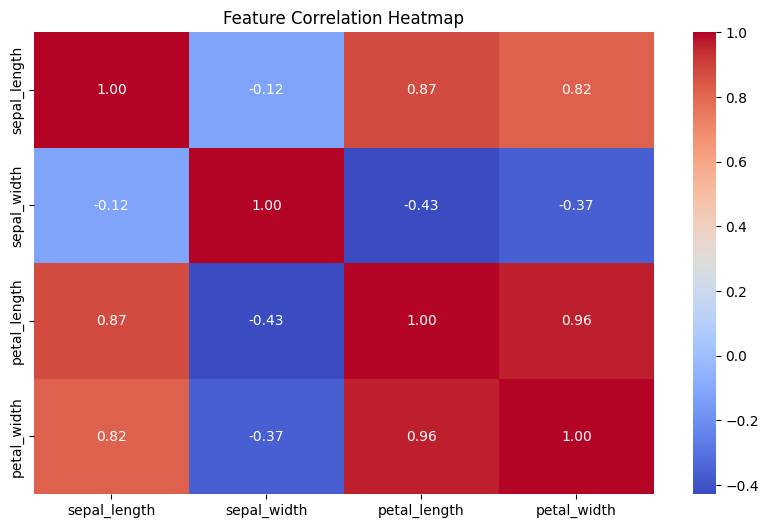

In [9]:
plt.figure(figsize=(10, 6))
correlation = df.drop(columns=['species']).corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Feature Correlation Heatmap')
plt.show()

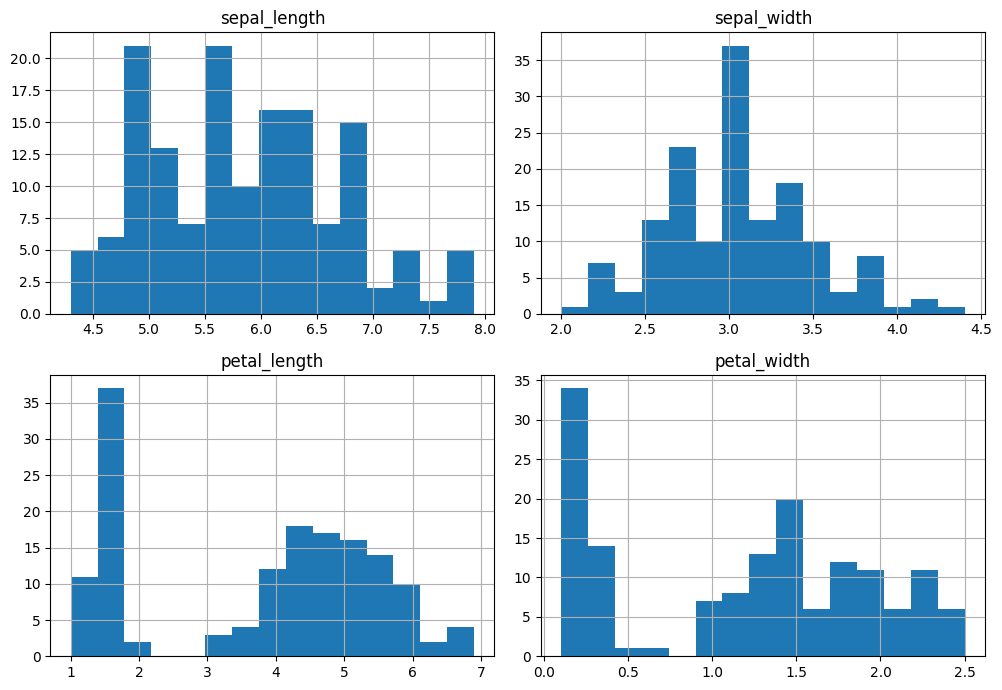

In [10]:
df.hist(figsize=(10, 7), bins=15)
plt.tight_layout()
plt.show()

In [11]:
X = df.drop('species', axis=1)
y = df['species']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
log_model = LogisticRegression(max_iter=200)
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=200)

In [15]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_scaled, y_train)


DecisionTreeClassifier(random_state=42)

In [16]:
y_pred_log = log_model.predict(X_test_scaled)
y_pred_tree = tree_model.predict(X_test_scaled)

In [17]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_tree
})
print(comparison.head(10))

       Actual Logistic Regression Decision Tree
0      setosa              setosa        setosa
1   virginica           virginica     virginica
2  versicolor          versicolor    versicolor
3  versicolor          versicolor    versicolor
4      setosa              setosa        setosa
5  versicolor          versicolor    versicolor
6      setosa              setosa        setosa
7      setosa              setosa        setosa
8   virginica           virginica     virginica
9  versicolor          versicolor    versicolor


In [18]:
log_accuracy = accuracy_score(y_test, y_pred_log)
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Logistic Regression Accuracy:", log_accuracy)
print("Decision Tree Accuracy:", tree_accuracy)

Logistic Regression Accuracy: 0.9333333333333333
Decision Tree Accuracy: 0.9333333333333333


In [19]:
# Logistic Regression Metrics
log_precision = precision_score(
    y_test, y_pred_log, average='macro'
)
log_recall = recall_score(
    y_test, y_pred_log, average='macro'
)
log_f1 = f1_score(
    y_test, y_pred_log, average='macro'
)

print("Logistic Regression Report")
print(classification_report(y_test, y_pred_log))

Logistic Regression Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [20]:
# Decision Tree Metrics
tree_precision = precision_score(
    y_test, y_pred_tree, average='macro'
)
tree_recall = recall_score(
    y_test, y_pred_tree, average='macro'
)
tree_f1 = f1_score(
    y_test, y_pred_tree, average='macro'
)

print("Decision Tree Report")
print(classification_report(y_test, y_pred_tree))

Decision Tree Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



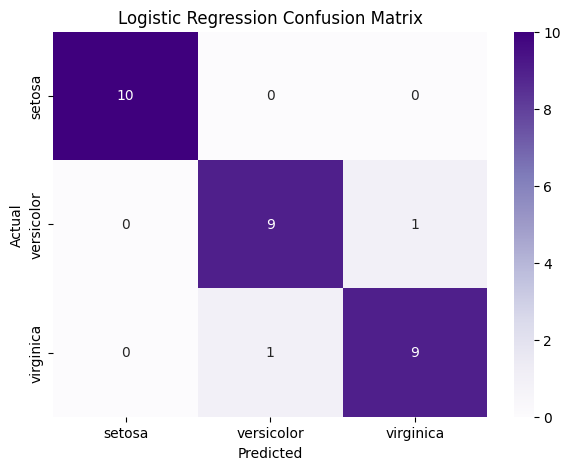

In [21]:
cm_log = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=log_model.classes_,
    yticklabels=log_model.classes_
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')

plt.show()

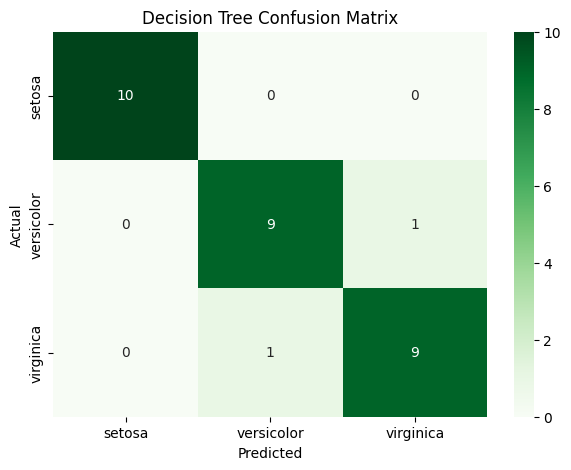

In [22]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=tree_model.classes_,
    yticklabels=tree_model.classes_
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix')

plt.show()

In [23]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [log_accuracy, tree_accuracy],
    'Precision': [log_precision, tree_precision],
    'Recall': [log_recall, tree_recall],
    'F1-Score': [log_f1, tree_f1]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.933333   0.933333  0.933333  0.933333
1        Decision Tree  0.933333   0.933333  0.933333  0.933333


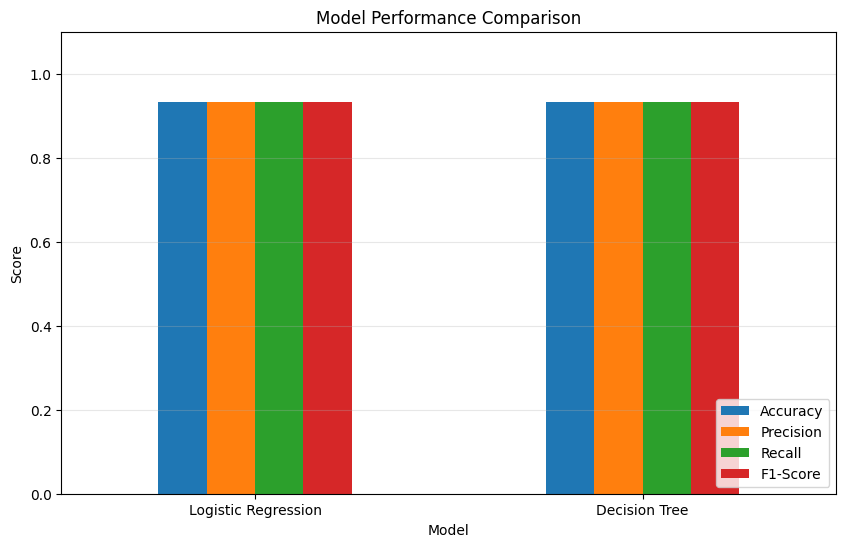

In [24]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [25]:
# Select two features
X_vis = df[['petal_length', 'petal_width']]

# Target variable
y_vis = df['species']

In [26]:
X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(
    X_vis,
    y_vis,
    test_size=0.2,
    random_state=42,
    stratify=y_vis
)

In [27]:
scaler_vis = StandardScaler()

X_train_vis_scaled = scaler_vis.fit_transform(X_train_vis)
X_test_vis_scaled = scaler_vis.transform(X_test_vis)

In [28]:
# Logistic Regression
log_vis_model = LogisticRegression(max_iter=200)
log_vis_model.fit(X_train_vis_scaled, y_train_vis)

LogisticRegression(max_iter=200)

In [29]:
# Decision Tree
tree_vis_model = DecisionTreeClassifier(random_state=42)
tree_vis_model.fit(X_train_vis_scaled, y_train_vis)

DecisionTreeClassifier(random_state=42)

In [30]:
# Create coordinate ranges
x_min, x_max = X_train_vis_scaled[:, 0].min() - 1, X_train_vis_scaled[:, 0].max() + 1
y_min, y_max = X_train_vis_scaled[:, 1].min() - 1, X_train_vis_scaled[:, 1].max() + 1

# Create meshgrid
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

In [31]:
grid_points = np.c_[xx.ravel(), yy.ravel()]

In [32]:
Z_log = log_vis_model.predict(grid_points)
Z_tree = tree_vis_model.predict(grid_points)

In [33]:
Z_log = Z_log.reshape(xx.shape)
Z_tree = Z_tree.reshape(xx.shape)

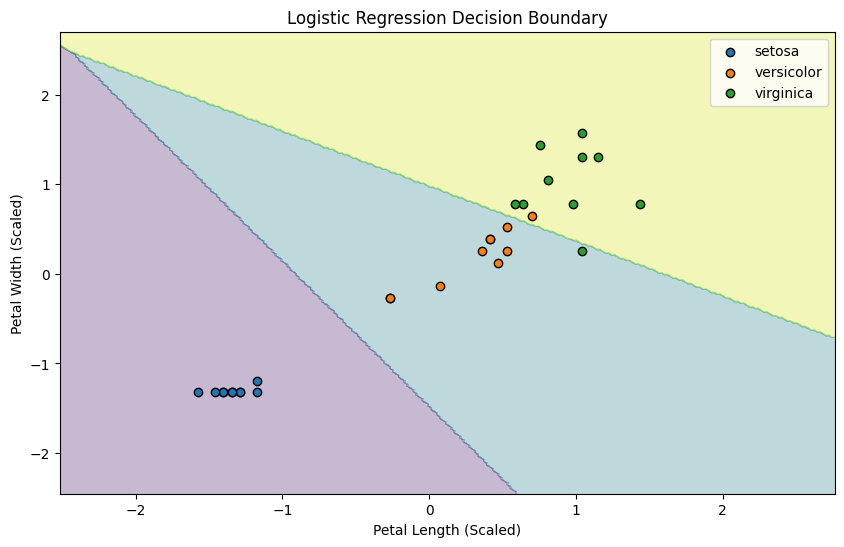

In [34]:
# Convert predicted species into numerical values
class_mapping = {
    class_name: index
    for index, class_name in enumerate(log_vis_model.classes_)
}

Z_log_num = np.vectorize(class_mapping.get)(Z_log)

# Plot Logistic Regression decision boundary
plt.figure(figsize=(10, 6))

plt.contourf(
    xx,
    yy,
    Z_log_num,
    alpha=0.3,
    cmap='viridis'
)

# Plot actual data points
for class_name, index in class_mapping.items():

    plt.scatter(
        X_test_vis_scaled[y_test_vis.values == class_name, 0],
        X_test_vis_scaled[y_test_vis.values == class_name, 1],
        label=class_name,
        edgecolors='black'
    )

plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.title('Logistic Regression Decision Boundary')
plt.legend()
plt.show()

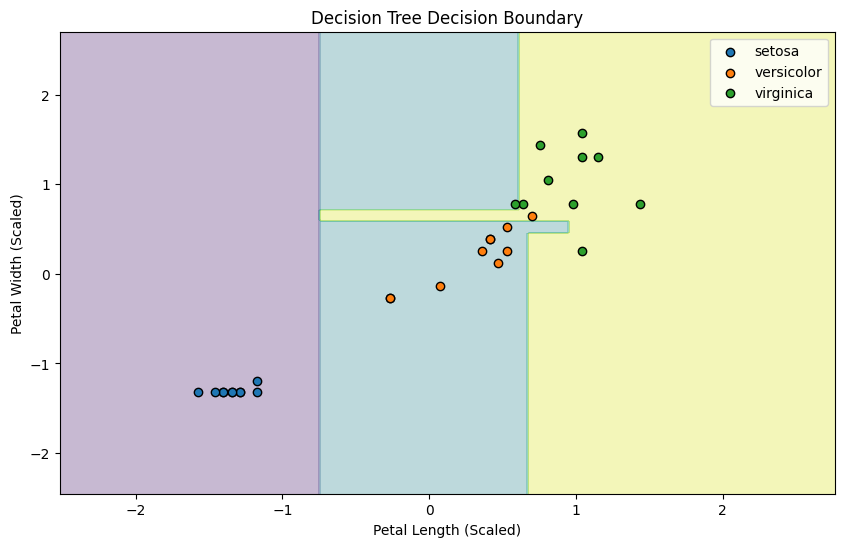

In [35]:
# Convert predicted species into numerical values
Z_tree_num = np.vectorize(class_mapping.get)(Z_tree)

# Plot Decision Tree decision boundary
plt.figure(figsize=(10, 6))

plt.contourf(
    xx,
    yy,
    Z_tree_num,
    alpha=0.3,
    cmap='viridis'
)

# Plot actual data points
for class_name, index in class_mapping.items():

    plt.scatter(
        X_test_vis_scaled[y_test_vis.values == class_name, 0],
        X_test_vis_scaled[y_test_vis.values == class_name, 1],
        label=class_name,
        edgecolors='black'
    )

plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.title('Decision Tree Decision Boundary')
plt.legend()
plt.show()

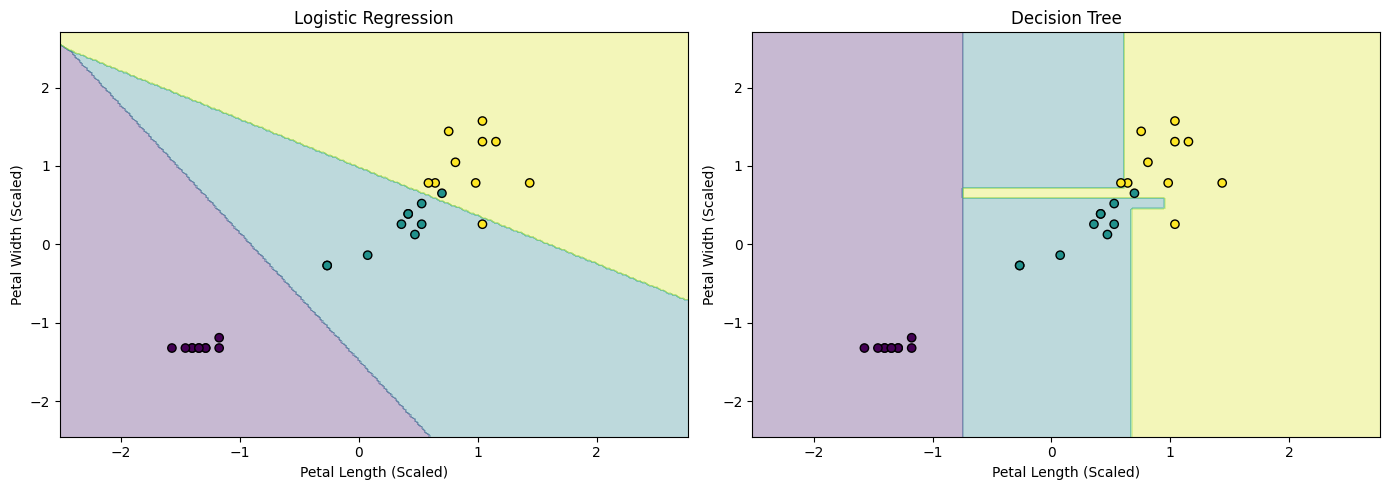

In [36]:
# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Decision Boundary
axes[0].contourf(
    xx,
    yy,
    Z_log_num,
    alpha=0.3,
    cmap='viridis'
)

axes[0].scatter(
    X_test_vis_scaled[:, 0],
    X_test_vis_scaled[:, 1],
    c=[class_mapping[label] for label in y_test_vis],
    edgecolors='black'
)

axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Petal Length (Scaled)')
axes[0].set_ylabel('Petal Width (Scaled)')


# Decision Tree Decision Boundary
axes[1].contourf(
    xx,
    yy,
    Z_tree_num,
    alpha=0.3,
    cmap='viridis'
)

axes[1].scatter(
    X_test_vis_scaled[:, 0],
    X_test_vis_scaled[:, 1],
    c=[class_mapping[label] for label in y_test_vis],
    edgecolors='black'
)

axes[1].set_title('Decision Tree')
axes[1].set_xlabel('Petal Length (Scaled)')
axes[1].set_ylabel('Petal Width (Scaled)')

plt.tight_layout()
plt.show()

In [37]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

In [38]:
# Create Logistic Regression pipeline
log_cv_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=200)
)

# Perform 5-Fold Cross Validation
log_cv_scores = cross_val_score(
    log_cv_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

# Display scores
print("Logistic Regression CV Scores:", log_cv_scores)

print("Mean Accuracy:", log_cv_scores.mean())

Logistic Regression CV Scores: [0.96666667 1.         0.93333333 0.9        1.        ]
Mean Accuracy: 0.9600000000000002


In [39]:
# Create Decision Tree model
tree_cv_model = DecisionTreeClassifier(random_state=42)

# Perform 5-Fold Cross Validation
tree_cv_scores = cross_val_score(
    tree_cv_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

# Display scores
print("Decision Tree CV Scores:", tree_cv_scores)

print("Mean Accuracy:", tree_cv_scores.mean())

Decision Tree CV Scores: [0.96666667 0.96666667 0.9        0.93333333 1.        ]
Mean Accuracy: 0.9533333333333334


In [40]:
cv_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Mean CV Accuracy': [
        log_cv_scores.mean(),
        tree_cv_scores.mean()
    ]
})
print(cv_results)

                 Model  Mean CV Accuracy
0  Logistic Regression          0.960000
1        Decision Tree          0.953333


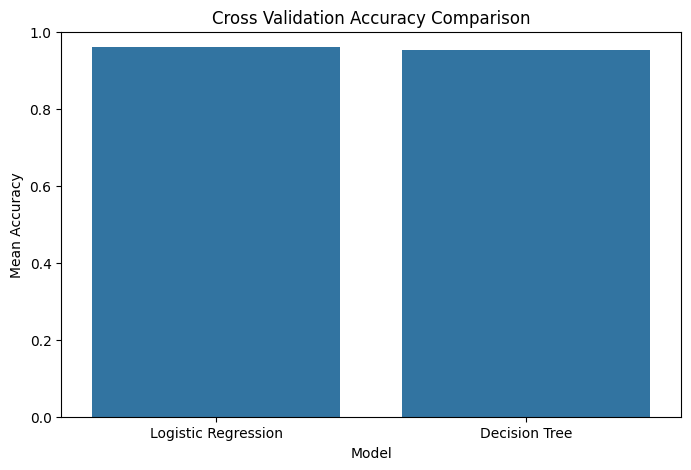

In [41]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=cv_results,
    x='Model',
    y='Mean CV Accuracy'
)

plt.title('Cross Validation Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 1)

plt.show()

In [42]:
# Calculate mean and standard deviation of cross-validation scores
cv_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],

    'Mean Accuracy': [
        log_cv_scores.mean(),
        tree_cv_scores.mean()
    ],

    'Standard Deviation': [
        log_cv_scores.std(),
        tree_cv_scores.std()
    ]
})

print(cv_summary)

                 Model  Mean Accuracy  Standard Deviation
0  Logistic Regression       0.960000            0.038873
1        Decision Tree       0.953333            0.033993


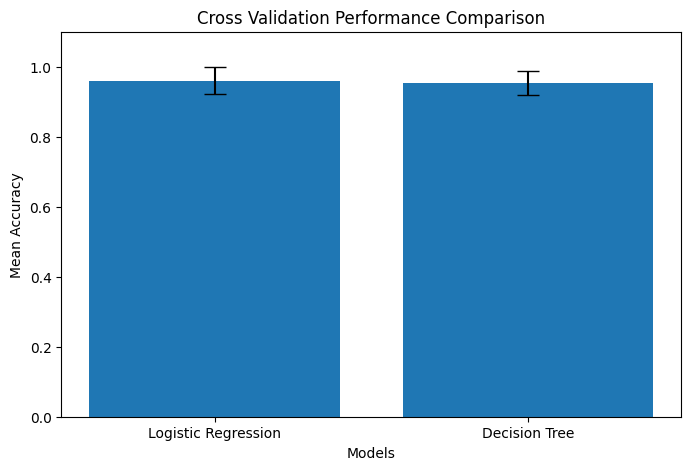

In [43]:
# Get mean accuracy and standard deviation
means = [
    log_cv_scores.mean(),
    tree_cv_scores.mean()
]

stds = [
    log_cv_scores.std(),
    tree_cv_scores.std()
]

models = ['Logistic Regression', 'Decision Tree']

# Create bar chart with error bars
plt.figure(figsize=(8, 5))

plt.bar(
    models,
    means,
    yerr=stds,
    capsize=8
)

plt.title('Cross Validation Performance Comparison')
plt.xlabel('Models')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 1.1)

plt.show()

In [44]:
# Create final Logistic Regression model
final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=200)
)

# Train using the full dataset
final_model.fit(X, y)

print("Final Model Training Completed!")

Final Model Training Completed!


In [45]:
import joblib
joblib.dump(final_model, 'iris_logistic_model.pkl')

print("Model Saved Successfully!")

Model Saved Successfully!


In [46]:
# Load the saved model
loaded_model = joblib.load('iris_logistic_model.pkl')

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [50]:
# New flower data
new_flower = [[4.0, 2.7, 3.1, 5.2]]

# Predict the species
prediction = loaded_model.predict(new_flower)

print("Predicted Species:", prediction[0])

Predicted Species: virginica


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
